In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

SOLAR = "../data/raw/solar"

gen1 = pd.read_csv(f"{SOLAR}/Plant_1_Generation_Data.csv")
gen1["DATE_TIME"] = pd.to_datetime(gen1["DATE_TIME"], dayfirst=True)
gen2 = pd.read_csv(f"{SOLAR}/Plant_2_Generation_Data.csv")
gen2["DATE_TIME"] = pd.to_datetime(gen2["DATE_TIME"])
wx1 = pd.read_csv(f"{SOLAR}/Plant_1_Weather_Sensor_Data.csv")
wx2 = pd.read_csv(f"{SOLAR}/Plant_2_Weather_Sensor_Data.csv")
wx = pd.concat([wx1, wx2], ignore_index=True)
wx["DATE_TIME"] = pd.to_datetime(wx["DATE_TIME"])

gen = pd.concat([gen1, gen2], ignore_index=True)
df = gen.merge(
    wx[["DATE_TIME", "PLANT_ID", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]],
    on=["DATE_TIME", "PLANT_ID"], how="left")
df["date"] = df["DATE_TIME"].dt.date
print(df.shape, "| rows with no weather match:", int(df["IRRADIATION"].isna().sum()))

(136476, 11) | rows with no weather match: 4


In [2]:
ratio = (df[df["DC_POWER"] > 0].groupby("PLANT_ID")
         .apply(lambda g: g["AC_POWER"].sum() / g["DC_POWER"].sum()))
print(ratio)

PLANT_ID
4135001    0.097795
4136001    0.978013
dtype: float64


In [3]:
DAY = 0.1   # irradiation threshold for "sun is up"

wx["date"] = wx["DATE_TIME"].dt.date
expected = (wx.assign(day=wx["IRRADIATION"] > DAY)
              .groupby(["PLANT_ID", "date"])["day"].sum()
              .rename("expected_intervals").reset_index())
print(expected.head())

   PLANT_ID        date  expected_intervals
0   4135001  2020-05-15                  42
1   4135001  2020-05-16                  42
2   4135001  2020-05-17                  42
3   4135001  2020-05-18                  38
4   4135001  2020-05-19                  39


In [4]:
df["energy_kwh"] = df["AC_POWER"] * 0.25     # 15-minute readings, kW to kWh

energy = (df.groupby(["PLANT_ID", "SOURCE_KEY", "date"])
            .agg(energy_kwh=("energy_kwh", "sum"),
                 max_ac_kw=("AC_POWER", "max"))
            .reset_index())

producing = (df[df["IRRADIATION"] > DAY]
             .assign(on=lambda x: x["AC_POWER"] > 0)
             .groupby(["PLANT_ID", "SOURCE_KEY", "date"])["on"].sum()
             .rename("producing_intervals").reset_index())

sun = (wx.groupby(["PLANT_ID", "date"])["IRRADIATION"].sum() * 0.25).rename("sun_kwh_m2").reset_index()

inv_day = (energy.merge(producing, on=["PLANT_ID", "SOURCE_KEY", "date"], how="left")
                 .merge(expected, on=["PLANT_ID", "date"], how="left")
                 .merge(sun, on=["PLANT_ID", "date"], how="left"))
inv_day["producing_intervals"] = inv_day["producing_intervals"].fillna(0)
inv_day["availability_pct"] = (inv_day["producing_intervals"] / inv_day["expected_intervals"] * 100).clip(upper=100)
inv_day["yield_per_sun"] = inv_day["energy_kwh"] / inv_day["sun_kwh_m2"]

# compare each inverter with the median inverter of its plant on the same day
inv_day["rel_perf"] = inv_day["yield_per_sun"] / inv_day.groupby(["PLANT_ID", "date"])["yield_per_sun"].transform("median")
print(inv_day.shape)
display(inv_day.describe().T)

(1464, 11)


,count,mean,std,min,25%,50%,75%,max
PLANT_ID,1464.0,4.135490e+06,500.051355,4.135001e+06,4.135001e+06,4.135001e+06,4.136001e+06,4.136001e+06
energy_kwh,1464.0,6.404386e+03,1844.604917,7.291529e+02,5.418617e+03,6.564940e+03,7.827675e+03,9.875882e+03
max_ac_kw,1464.0,1.162639e+03,174.746897,5.337643e+02,1.092874e+03,1.227807e+03,1.282969e+03,1.410950e+03
producing_intervals,1464.0,3.804577e+01,6.750607,7.000000e+00,3.600000e+01,4.100000e+01,4.200000e+01,4.500000e+01
expected_intervals,1464.0,4.097131e+01,3.646813,2.400000e+01,4.000000e+01,4.200000e+01,4.300000e+01,4.600000e+01
sun_kwh_m2,1464.0,5.428090e+00,1.067967,2.819491e+00,4.644081e+00,5.508408e+00,6.234295e+00,7.139764e+00
availability_pct,1464.0,9.307460e+01,14.966276,1.666667e+01,9.750000e+01,1.000000e+02,1.000000e+02,1.000000e+02
yield_per_sun,1464.0,1.198312e+03,291.916588,1.255147e+02,1.217304e+03,1.313537e+03,1.362975e+03,1.498137e+03
rel_perf,1464.0,9.500855e-01,0.249494,1.097430e-01,9.567011e-01,1.000000e+00,1.020477e+00,3.566742e+00


,PLANT_ID,SOURCE_KEY,median_rel_perf,mean_availability
33,4136001,Quc1TzYxW2pYoWX,0.596548,78.489514
25,4136001,Et9kgGMDl729KT4,0.712483,76.655007
27,4136001,LYwnQax7tkwH5Cb,0.803039,77.646682
40,4136001,rrq4fwE8jgrTyWY,0.835227,81.363037
11,4135001,bvBOhCH3iADSZry,0.918850,98.624905
0,4135001,1BY6WEcLGh8j5v7,0.930043,98.691749
39,4136001,q49J1IKaHRwDQnt,0.957435,83.243504
13,4135001,ih0vzX44oOqAx2f,0.979767,99.924585


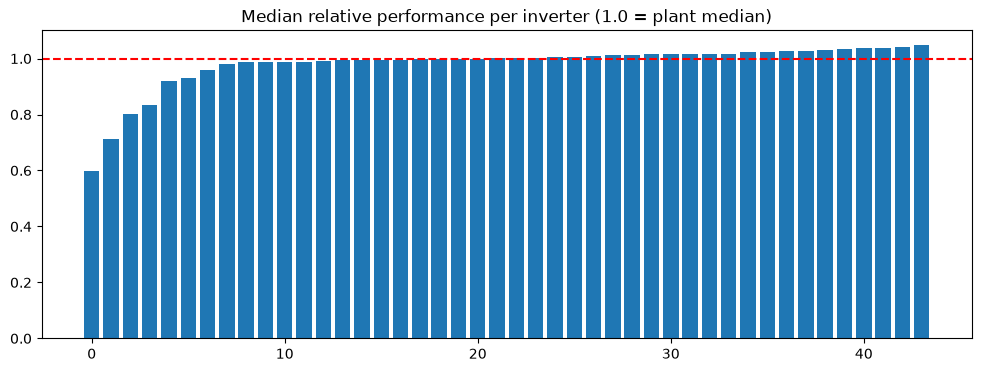

In [5]:
rank = (inv_day.groupby(["PLANT_ID", "SOURCE_KEY"])
               .agg(median_rel_perf=("rel_perf", "median"),
                    mean_availability=("availability_pct", "mean"))
               .reset_index().sort_values("median_rel_perf"))
display(rank.head(8))

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(rank)), rank["median_rel_perf"])
ax.axhline(1.0, color="red", ls="--")
ax.set_title("Median relative performance per inverter (1.0 = plant median)")
plt.show()

In [6]:
os.makedirs("../data/clean", exist_ok=True)
inv_day.to_parquet("../data/clean/solar_inverter_day.parquet", index=False)
wx.to_parquet("../data/clean/solar_weather.parquet", index=False)
print("saved")

saved
